In [2]:
import torch
from torch import nn
import torchvision
import torchvision.transforms as T
import torch.nn.functional as F
import matplotlib.pyplot as plt
transform = T.Compose([T.ToTensor()])
train_set = torchvision.datasets.MNIST(root = '/data/train', train = True,
                                       download = True, transform = transform)
test_set = torchvision.datasets.MNIST(root = '/data/test', train = False,
                                      download = True, transform = transform)
batch_size = 32
train_loader = torch.utils.data.DataLoader(
    train_set, batch_size = batch_size, shuffle = True)
test_loader = torch.utils.data.DataLoader(
    test_set, batch_size = batch_size, shuffle = True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.36MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 114kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.23MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.01MB/s]
100%|██████████| 9.91M/9.91M [00:02<00:00, 3.74MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 109kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.06MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.97MB/s]


In [9]:
class AE(nn.Module):
    def __init__(self, input_dim, z_dim, h_dim):
        super().__init__()
        self.common = nn.Linear(input_dim, h_dim)
        self.encoded = nn.Linear(h_dim, z_dim)
        self.l1 = nn.Linear(z_dim, h_dim)
        self.decoded = nn.Linear(h_dim, input_dim)

    def encoder(self, x):
        common = F.relu(self.common(x))
        mu = self.encoded(common)
        return mu

    def decoder(self, z):
        out = F.relu(self.l1(z))
        out = torch.sigmoid(self.decoded(out))
        return out

    def forward(self, x):
        mu = self.encoder(x)
        out = self.decoder(mu)
        return out, mu

In [10]:
def eval(model):
    model.eval()
    original = []
    idx = 0
    for images, labels in test_set:
        if labels == idx:
            original.append(images)
            idx += 1
        if idx == 10:
            break
    reconstructed = []
    for idx in range(10):
        with torch.no_grad():
            img = original[idx].reshape(1, input_dim)
            out, mu = model(img.to(device))

        reconstructed.append(out)
    imgs = original + reconstructed
    plt.figure(figsize = (10, 2), dpi = 50)
    for i in range(20):
        ax = plt.subplot(2, 10, i + 1)
        img = (imgs[i]).detach().cpu().numpy()
        plt.imshow(img.reshape(28, 28), cmap = 'binary')
        plt.xticks([])
        plt.yticks([])
    plt.show()

at epoch 1 avg loss = 1004.5735783040365


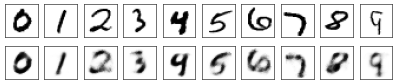

at epoch 2 avg loss = 476.3063334472656


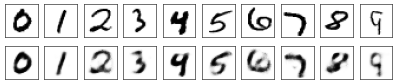

at epoch 3 avg loss = 390.45552810872397


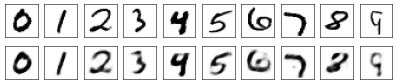

at epoch 4 avg loss = 352.9216756835938


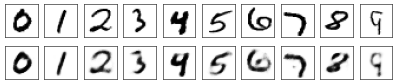

at epoch 5 avg loss = 328.7623804199219


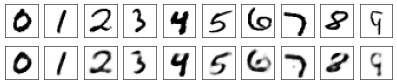

at epoch 6 avg loss = 310.9414836751302


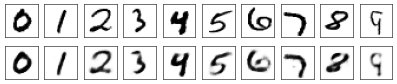

at epoch 7 avg loss = 296.8842666666667


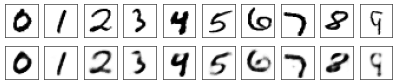

at epoch 8 avg loss = 285.2630884765625


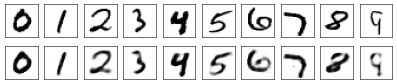

at epoch 9 avg loss = 275.6604935953776


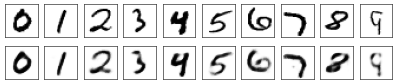

at epoch 10 avg loss = 267.536438671875


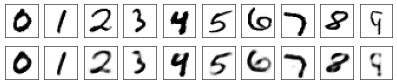

at epoch 11 avg loss = 260.43411550292967


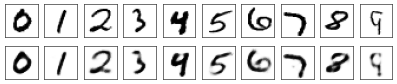

at epoch 12 avg loss = 254.33262205403645


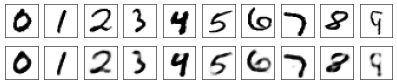

at epoch 13 avg loss = 248.96869260253905


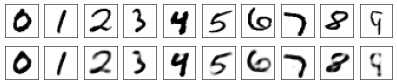

at epoch 14 avg loss = 244.2935698811849


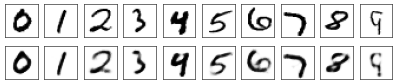

at epoch 15 avg loss = 240.17388298339844


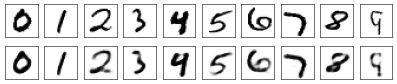

at epoch 16 avg loss = 236.60849375813802


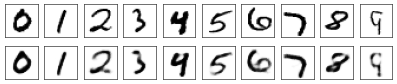

at epoch 17 avg loss = 233.33991569010416


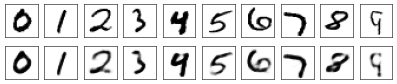

at epoch 18 avg loss = 230.35800418294272


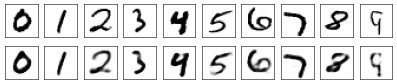

at epoch 19 avg loss = 227.73860511881512


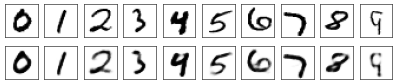

at epoch 20 avg loss = 225.36590848795572


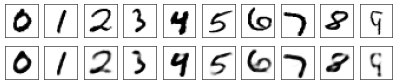

at epoch 21 avg loss = 223.1547967610677


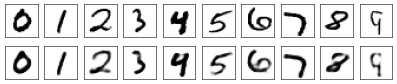

at epoch 22 avg loss = 221.2192080485026


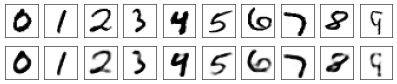

at epoch 23 avg loss = 219.3278732828776


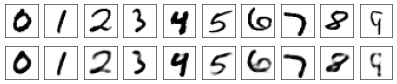

at epoch 24 avg loss = 217.66067272949218


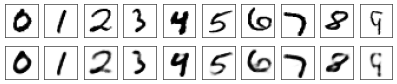

at epoch 25 avg loss = 216.00487263997397


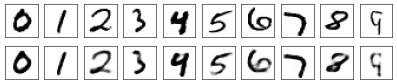

In [11]:
#----------------------------main---------------------------------
input_dim = 784
z_dim = 20
h_dim = 200
ae = AE(input_dim, z_dim, h_dim).to(device)
lr = 0.00025
trainer = torch.optim.Adam(ae.parameters(), lr = lr)

for epoch in range(25):
    t_loss = 0
    ae.train()
    for imgs, labels in train_loader:
        imgs = imgs.to(device).view(-1, input_dim)
        out, mu = ae(imgs)
        loss = ((out - imgs) ** 2).sum()
        trainer.zero_grad()
        loss.backward()
        trainer.step()
        t_loss += loss.item()

    print(f'at epoch {epoch + 1} avg loss = {t_loss / len(train_loader)}')
    eval(ae)